# Supplementary Figure 22 — derivation of the conservation-priority knee β_CON

The β_CON that fixes the **CON** and **IAP** signposts in Figure 4 is the **knee** of
the φ = 0 (BAU-demand) cost–benefit frontier over conservation priority β.

- **(a)** In normalized (cost  $x_n$ , ΔOverlap  $y_n$ ) space the knee is the frontier
  point **farthest above the endpoint chord** $y=x$, i.e. $\arg\max_\beta (y_n - x_n)$.
- **(b)** The net benefit $y_n - x_n$ vs β has a **flat top** at β = 0.6–0.7 (tied within
  Δ ≈ 1e‑4); we take **β_CON = 0.6**, the **cheaper end** of that plateau.

ΔOverlap = reduction in **mining-biodiversity overlap** (species-range equivalents),
versus BAU·β0. Central M/M demand/reserve case; same φ = 0 frontier as Figure 3.

> Run in the activated `wty` kernel (this env's numpy LAPACK crashes if Python starts
> without the env activated).

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

plt.rcParams['font.family'] = 'Arial'

In [ ]:
ROOT    = Path('..')
RESULTS = ROOT / 'results'
FIGURES = ROOT / 'figures'; FIGURES.mkdir(exist_ok=True)

DEMAND, RESERVE = 'M', 'M'        # central demand / reserve case

# Merge the two summary tables (per scenario × beta), same inputs as Figure 4.
cost = pd.read_csv(RESULTS / 'extraction-rasters' / f'cost-analysis-D{DEMAND}-R{RESERVE}.csv')
risk = pd.read_csv(RESULTS / 'biodiversity-risk' / f'biodiversity-risk-summary-D{DEMAND}-R{RESERVE}.csv')
df = cost.merge(risk, on=['scenario', 'beta'])

# Baseline = BAU·β0. 'overlap' = mining-biodiversity overlap (species-range equivalents).
base = df[(df.scenario == 'BAU') & (df.beta == 0.0)].iloc[0]
asr_bau = base['overlap']

# --- φ = 0 frontier: the BAU-demand scenario swept over conservation priority β ---
fr   = df[df.scenario == 'BAU'].sort_values('beta').reset_index(drop=True)
beta = fr['beta'].to_numpy()
red  = (1 - fr['overlap'] / asr_bau).to_numpy()          # ΔOverlap reduction fraction (pre-norm y)
cst  = fr['cost_Tusd_central'].to_numpy()                # cost (pre-norm x; affine-equiv to $/t at φ=0)

# normalize both axes onto the BAU·β0 -> β=1 endpoints
x_n = (cst - cst[0]) / (cst[-1] - cst[0])
y_n = (red - red[0]) / (red[-1] - red[0])
net = y_n - x_n                                          # vertical distance above the chord y = x

# knee = flat top of net benefit; pick the CHEAPER (lower-β) end of the tied plateau
TOL      = 1e-3
plateau  = beta[net >= net.max() - TOL]
beta_con = plateau.min()                                 # cheaper end  -> β_CON
beta_tie = plateau.max()                                 # the tied (more expensive) end
i_con    = int(np.where(beta == beta_con)[0][0])
i_tie    = int(np.where(beta == beta_tie)[0][0])
delta     = abs(round(net[i_tie], 4) - round(net[i_con], 4))   # 4-dp tie gap  (≈ 1e-4)
delta_str = f'{delta:.0e}'.replace('e-0', 'e-')                # -> '1e-4'

print(f'β_CON = {beta_con:g} (cheaper end);  tied with β = {beta_tie:g}  (Δ net = {delta_str})')
print(f'  knee point:  x_n = {x_n[i_con]:.3f},  y_n = {y_n[i_con]:.3f},  net = {net[i_con]:.4f}')

β_CON = 0.6 (cheaper end);  tied with β = 0.7  (Δ net = 1e-4)
  knee point:  x_n = 0.163,  y_n = 0.680,  net = 0.5169


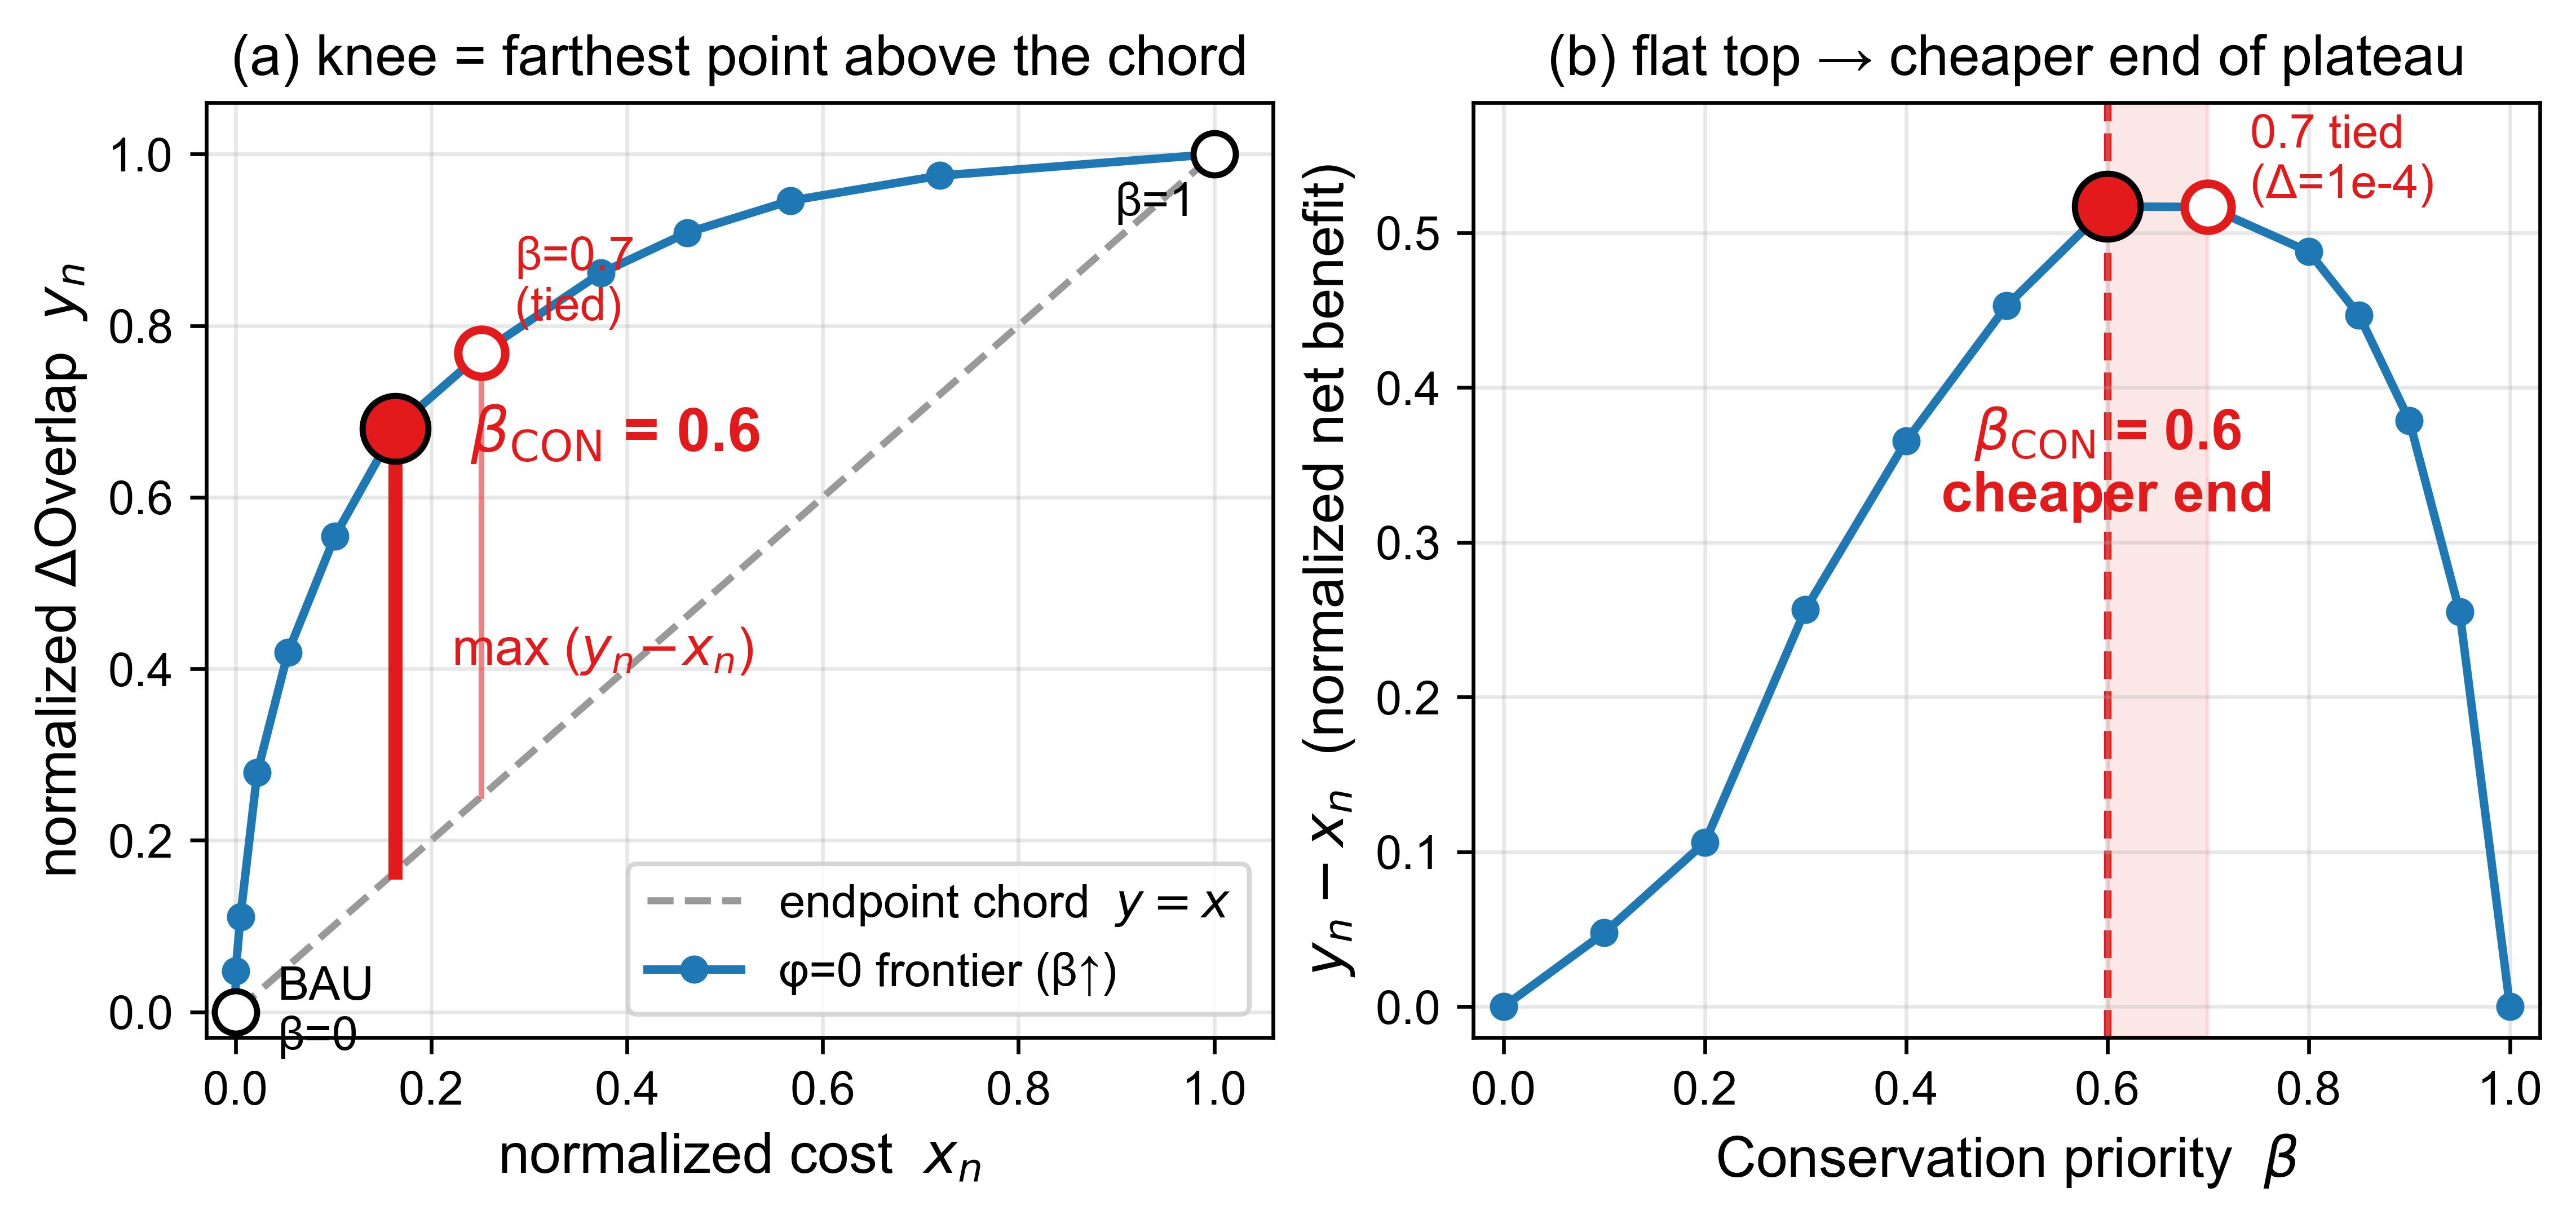

In [ ]:
RED, BLUE = '#e31a1c', '#1f77b4'
fig, axes = plt.subplots(1, 2, figsize=(7.5, 3.5), constrained_layout=True)

# ---------- (a) frontier in normalized (cost, ΔOverlap) space ----------
ax = axes[0]
ax.plot([0, 1], [0, 1], '--', color='0.6', lw=1.5, label='endpoint chord  $y = x$', zorder=1)
ax.plot(x_n, y_n, '-o', color=BLUE, ms=5, lw=1.8, label='φ=0 frontier (β↑)', zorder=3)

# vertical max(y_n - x_n): thick at the knee, thin at the tied point
ax.plot([x_n[i_con]] * 2, [x_n[i_con], y_n[i_con]], '-', color=RED, lw=3.0, zorder=2)
ax.plot([x_n[i_tie]] * 2, [x_n[i_tie], y_n[i_tie]], '-', color=RED, lw=1.2, alpha=0.55, zorder=2)
ax.annotate(r'max ($y_n\!-\!x_n$)', (x_n[i_con], (x_n[i_con] + y_n[i_con]) / 2),
            xytext=(12, 0), textcoords='offset points', color=RED, fontsize=11, va='center')

# endpoints + knee + tied markers
ax.plot(0, 0, 'o', mfc='white', mec='k', mew=1.3, ms=9, zorder=5)
ax.plot(1, 1, 'o', mfc='white', mec='k', mew=1.3, ms=9, zorder=5)
ax.plot(x_n[i_con], y_n[i_con], 'o', mfc=RED, mec='k', mew=1.3, ms=14, zorder=6)
ax.plot(x_n[i_tie], y_n[i_tie], 'o', mfc='white', mec=RED, mew=1.8, ms=10, zorder=6)

ax.annotate('BAU\nβ=0', (0, 0), xytext=(9, 0), textcoords='offset points', fontsize=10, va='center')
ax.annotate('β=1', (1, 1), xytext=(-4, -13), textcoords='offset points', fontsize=10, ha='right')
ax.annotate(r'$\beta_{\mathrm{CON}}$ = 0.6', (x_n[i_con], y_n[i_con]), xytext=(16, -1),
            textcoords='offset points', color=RED, fontsize=13, fontweight='bold', va='center')
ax.annotate('β=0.7\n(tied)', (x_n[i_tie], y_n[i_tie]), xytext=(7, 7),
            textcoords='offset points', color=RED, fontsize=10)

ax.set_xlim(-0.03, 1.06); ax.set_ylim(-0.03, 1.06)
ax.set_xlabel(r'normalized cost  $x_n$', fontsize=12)
ax.set_ylabel(r'normalized ΔOverlap  $y_n$', fontsize=12)
ax.set_title('(a) knee = farthest point above the chord', fontsize=12)
ax.legend(loc='lower right', frameon=True, fontsize=10)
ax.grid(alpha=0.3)

# ---------- (b) net benefit vs β ----------
ax = axes[1]
ax.axvspan(beta_con, beta_tie, color=RED, alpha=0.10, zorder=0)
ax.axvline(beta_con, color=RED, ls='--', lw=1.6, zorder=1)
ax.plot(beta, net, '-o', color=BLUE, ms=5, lw=1.8, zorder=3)
ax.plot(beta_con, net[i_con], 'o', mfc=RED, mec='k', mew=1.3, ms=14, zorder=5)
ax.plot(beta_tie, net[i_tie], 'o', mfc='white', mec=RED, mew=1.8, ms=10, zorder=5)

ax.annotate(f'{beta_tie:g} tied\n(Δ={delta_str})', (beta_tie, net[i_tie]),
            xytext=(9, 2), textcoords='offset points', color=RED, fontsize=10)
ax.annotate(r'$\beta_{\mathrm{CON}}$ = 0.6' + '\ncheaper end', (beta_con, net[i_con] * 0.62),
            xytext=(0, 0), textcoords='offset points', color=RED, fontsize=12, fontweight='bold', ha='center')

ax.set_xlim(-0.03, 1.03); ax.set_ylim(-0.02, net.max() * 1.13)
ax.set_xlabel(r'Conservation priority  $\beta$', fontsize=12)
ax.set_ylabel(r'$y_n - x_n$  (normalized net benefit)', fontsize=12)
ax.set_title('(b) flat top → cheaper end of plateau', fontsize=12)
ax.grid(alpha=0.3)

fig.savefig(FIGURES / 'Supplementary-Figure-22.jpg', dpi=600, bbox_inches='tight')
plt.show()